In [ ]:
!pip install tensorflow tensorflow-datasets matplotlib seaborn scikit-learn

In [ ]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 5))

    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(chr(int(labels[i].numpy()) + 65))
        plt.axis("off")

    plt.tight_layout()
    plt.show()

NameError: name 'train_ds' is not defined

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:
(train_ds, test_ds), info = tfds.load(
    'emnist/letters',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Training examples:", info.splits['train'].num_examples)
print("Testing examples:", info.splits['test'].num_examples)
print("Number of classes:", info.features['label'].num_classes)

ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:
!pip install -U importlib_resources tensorflow-datasets

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("Setup successful!")

Setup successful!


In [ ]:
(train_ds, test_ds), info = tfds.load(
    'emnist/letters',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Training examples:", info.splits['train'].num_examples)
print("Testing examples:", info.splits['test'].num_examples)
print("Number of classes:", info.features['label'].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.IF3QFN_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.IF3QFN_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.
Dataset loaded successfully!
Training examples: 88800
Testing examples: 14800
Number of classes: 37


In [ ]:
print("Number of classes:", info.features['label'].num_classes)
print("Label names:")
print(info.features['label'].names)

Number of classes: 37
Label names:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36']


In [ ]:
for image, label in train_ds.take(1):
    print("Image shape:", image.shape)
    print("Label:", label.numpy())

Image shape: (28, 28, 1)
Label: 25


In [ ]:
import numpy as np

train_labels = np.array([
    int(label) for _, label in tfds.as_numpy(train_ds)
])

print("Unique labels:", np.unique(train_labels))
print("Number of actual labels:", len(np.unique(train_labels)))

Unique labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26]
Number of actual labels: 26


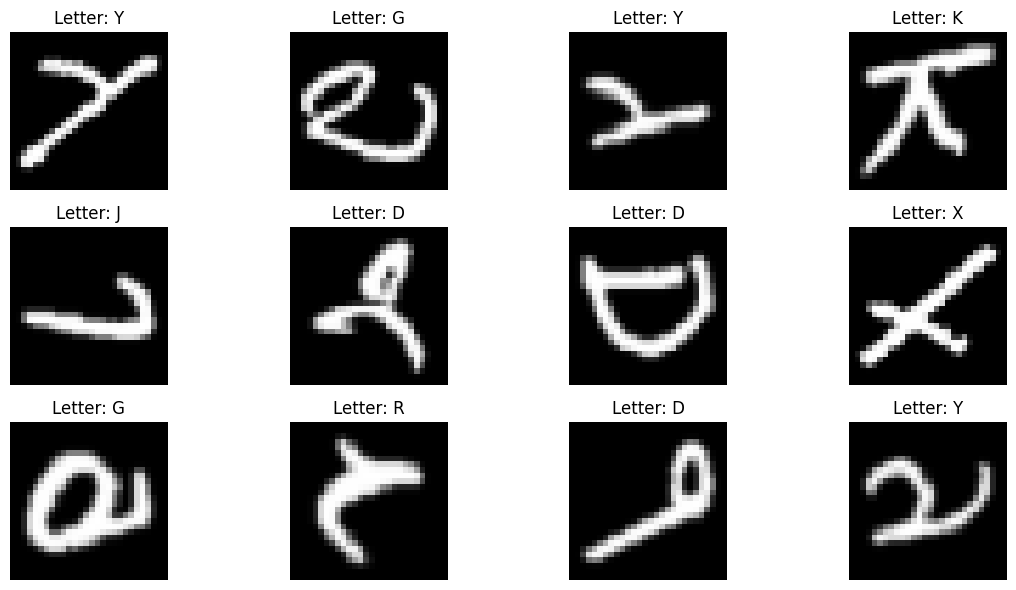

In [ ]:
plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(train_ds.take(12)):
    plt.subplot(3, 4, i + 1)

    plt.imshow(image.numpy().squeeze(), cmap='gray')
    plt.title(f"Letter: {chr(int(label) + 64)}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
def preprocess(image, label):
    image = tf.image.rot90(image, k=1)
    image = tf.cast(image, tf.float32) / 255.0
    label = label - 1
    return image, label

train_data = train_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_data = test_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Preprocessing completed!")

Preprocessing completed!


In [ ]:
BATCH_SIZE = 128

train_data = (
    train_data
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_data = (
    test_data
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and testing datasets are ready!")

Training and testing datasets are ready!


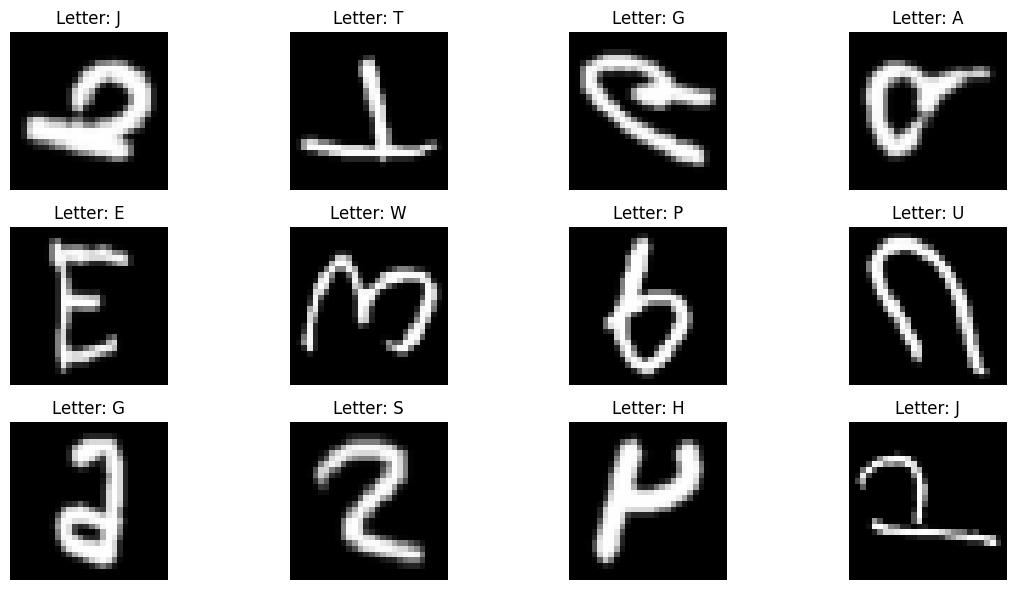

In [ ]:
plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(train_data.unbatch().take(12)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(image.numpy().squeeze(), cmap='gray')
    plt.title(f"Letter: {chr(int(label) + 65)}")
    plt.axis('off')

plt.tight_layout()
plt.show()

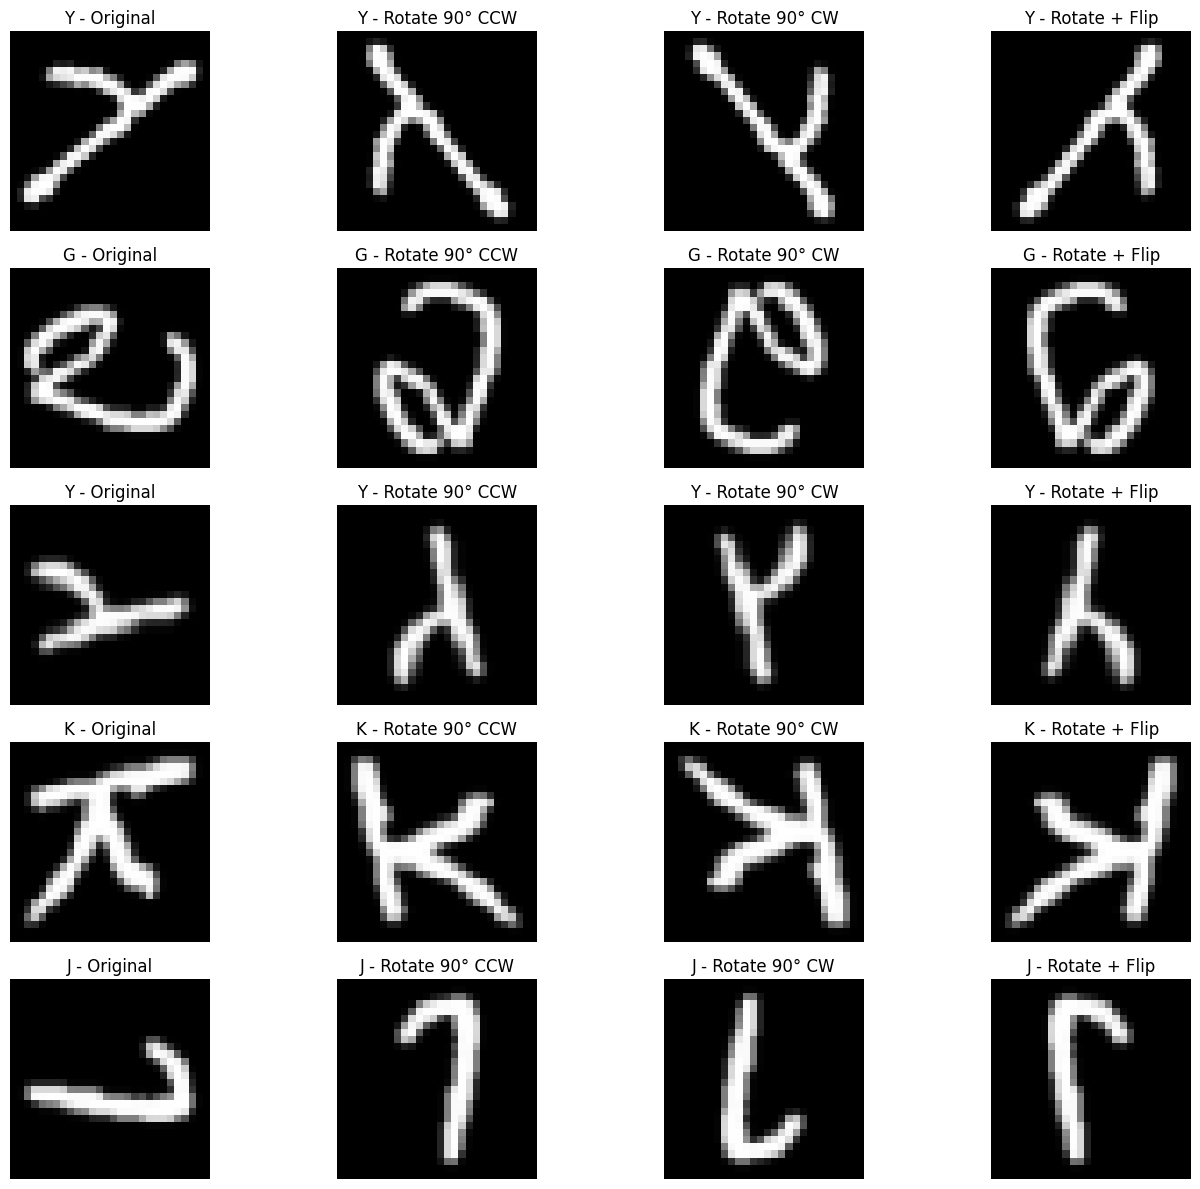

In [ ]:
plt.figure(figsize=(14, 12))

samples = list(train_ds.take(5))

for i, (image, label) in enumerate(samples):
    img = image.numpy().squeeze()
    letter = chr(int(label) + 64)

    versions = [
        img,
        np.rot90(img, 1),
        np.rot90(img, 3),
        np.fliplr(np.rot90(img, 1))
    ]

    names = ["Original", "Rotate 90° CCW",
             "Rotate 90° CW", "Rotate + Flip"]

    for j, version in enumerate(versions):
        plt.subplot(5, 4, i * 4 + j + 1)
        plt.imshow(version, cmap='gray')
        plt.title(f"{letter} - {names[j]}")
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
def preprocess(image, label):
    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.cast(image, tf.float32) / 255.0
    label = label - 1
    return image, label

print("Preprocessing function corrected!")

Preprocessing function corrected!


In [ ]:
train_data = train_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_data = test_ds.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 128

train_data = train_data.shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_data = test_data.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Datasets prepared successfully!")

Datasets prepared successfully!


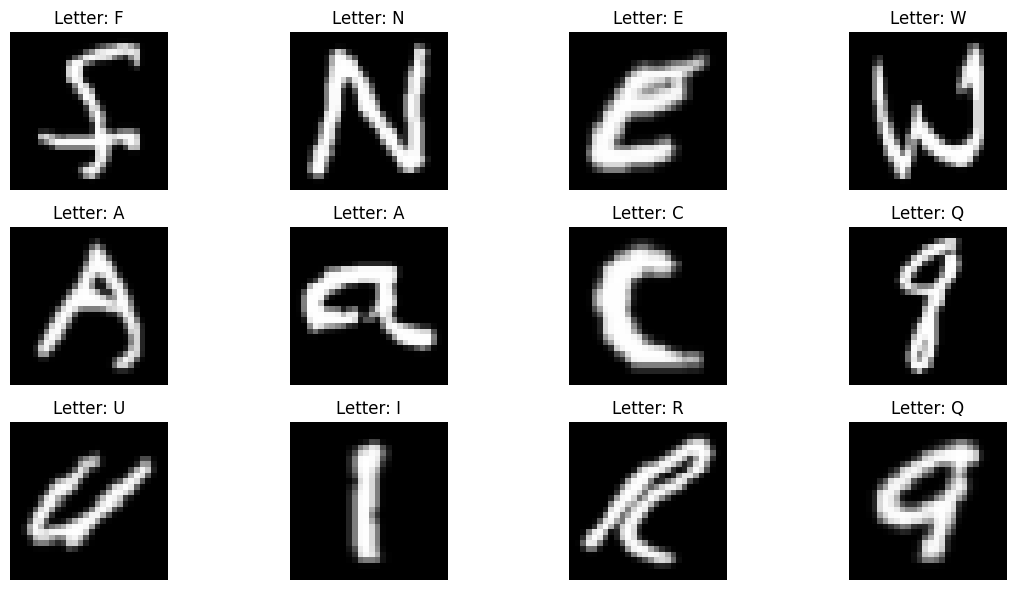

In [ ]:
plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(train_data.unbatch().take(12)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(image.numpy().squeeze(), cmap='gray')
    plt.title(f"Letter: {chr(int(label) + 65)}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(26, activation='softmax')
])

print("CNN model created successfully!")

CNN model created successfully!


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243,610 (951.60 KB)

 Trainable params: 243,610 (951.60 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 89s 124ms/step - accuracy: 0.7641 - loss: 0.7666 - val_accuracy: 0.8855 - val_loss: 0.3405
Epoch 2/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 133s 112ms/step - accuracy: 0.8958 - loss: 0.3212 - val_accuracy: 0.9107 - val_loss: 0.2633
Epoch 3/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 82s 112ms/step - accuracy: 0.9146 - loss: 0.2581 - val_accuracy: 0.9170 - val_loss: 0.2411
Epoch 4/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 76s 109ms/step - accuracy: 0.9238 - loss: 0.2252 - val_accuracy: 0.9208 - val_loss: 0.2273
Epoch 5/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 78s 111ms/step - accuracy: 0.9310 - loss: 0.2045 - val_accuracy: 0.9241 - val_loss: 0.2256
Epoch 6/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 87s 124ms/step - accuracy: 0.9354 - loss: 0.1857 - val_accuracy: 0.9228 - val_loss: 0.2158
Epoch 7/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 135s 114ms/step - accuracy: 0.9395 - loss: 0.1696 - val_accuracy: 0.9234 - val_loss: 0.2217
Epoch 8/15
694/694 ━━━━━━━━━━━━━━━━━━━━ 83s 116ms/step - accuracy: 0.9433 - loss:

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Model Evaluation Complete!")
print(f"Accuracy: {test_accuracy * 100:.2f}%")
print(f"Loss: {test_loss:.4f}")

116/116 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.9304 - loss: 0.2144
Model Evaluation Complete!
Accuracy: 93.04%
Loss: 0.2144


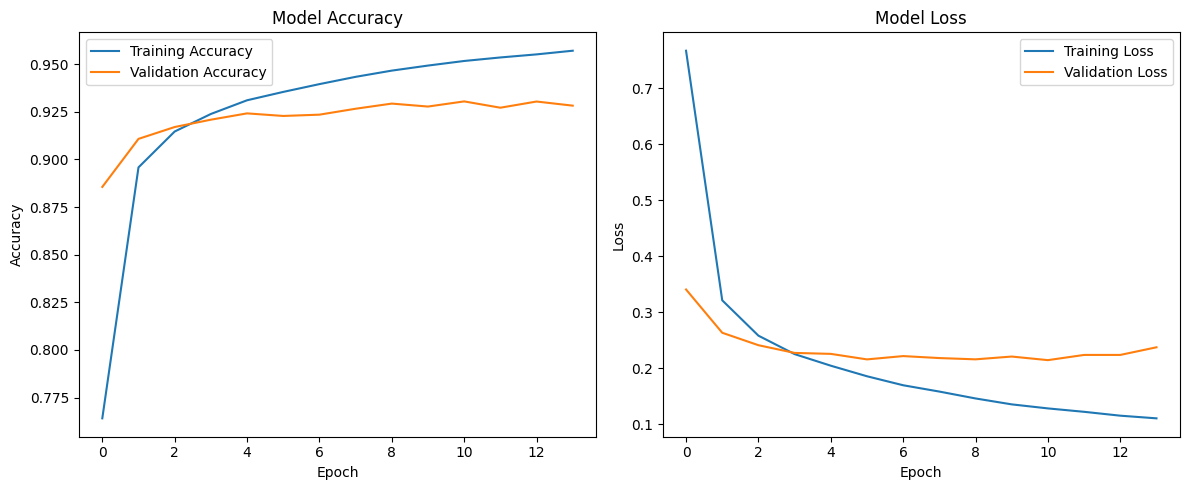

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
model.save("inkvision_model.keras")

print("InkVision AI model saved successfully!")

InkVision AI model saved successfully!


In [ ]:
from google.colab import files
files.download("inkvision_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

# Load EMNIST Letters dataset
(train_data, test_data), info = tfds.load(
    'emnist/letters',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")

# Get 10 original images
samples = list(train_data.take(10))

plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(samples):

    plt.subplot(2, 5, i + 1)

    plt.imshow(image.numpy().squeeze(), cmap='gray')

    letter = chr(int(label.numpy()) + 64)

    plt.title("Original: " + letter)
    plt.axis("off")

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:
!pip install importlib_resources

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.28W0P9_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.28W0P9_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.


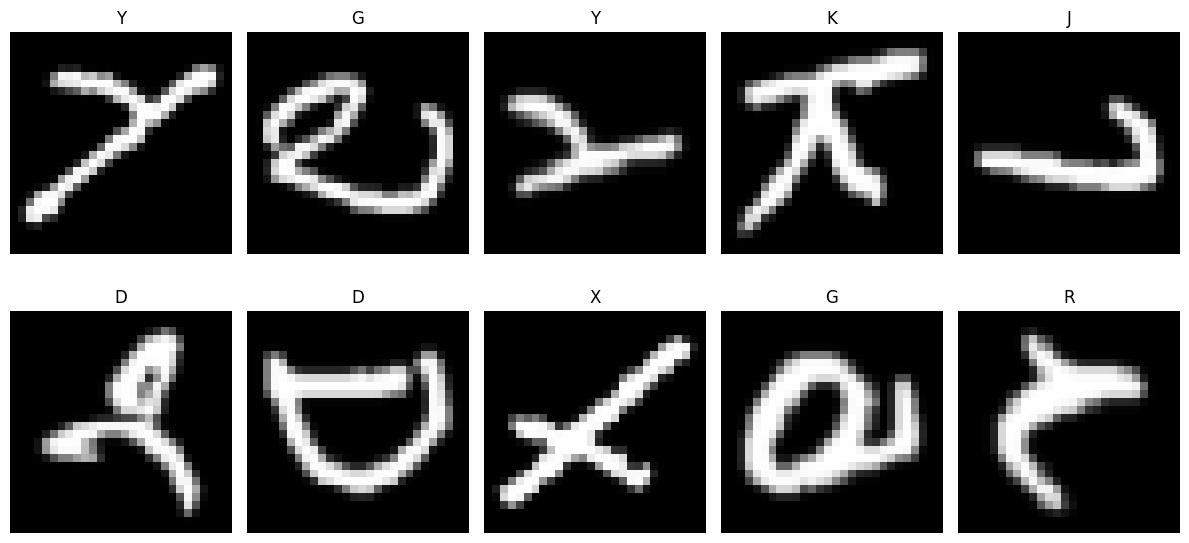

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

(train_data, test_data), info = tfds.load(
    'emnist/letters',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

samples = list(train_data.take(10))

plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(samples):
    plt.subplot(2, 5, i + 1)
    plt.imshow(image.numpy().squeeze(), cmap='gray')
    plt.title(chr(int(label.numpy()) + 64))
    plt.axis("off")

plt.tight_layout()
plt.show()

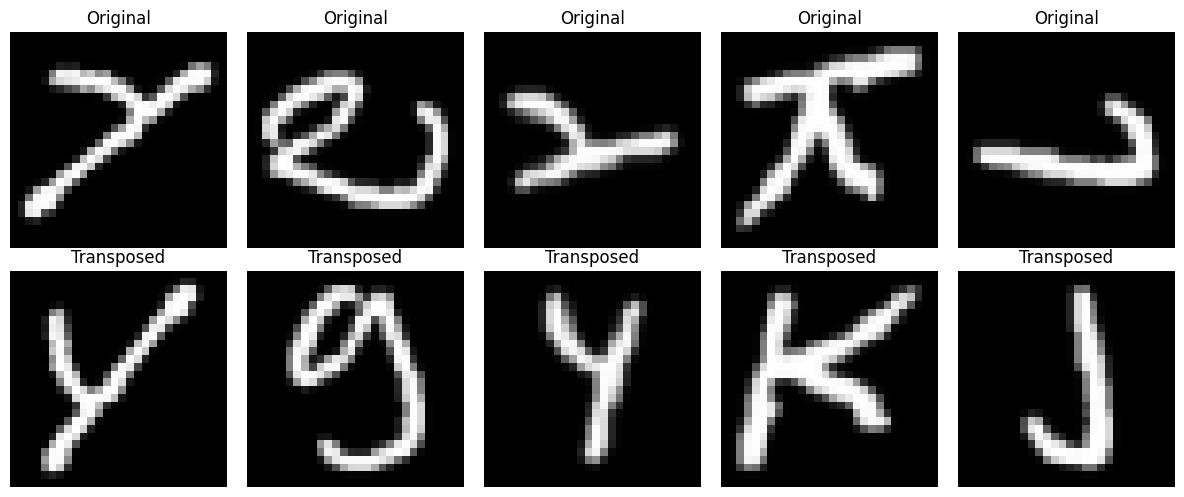

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

samples = list(train_data.take(5))

plt.figure(figsize=(12, 5))

for i, (image, label) in enumerate(samples):
    # Original image
    plt.subplot(2, 5, i + 1)
    plt.imshow(image.numpy().squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Transposed image
    corrected = tf.transpose(image, perm=[1, 0, 2])

    plt.subplot(2, 5, i + 6)
    plt.imshow(corrected.numpy().squeeze(), cmap="gray")
    plt.title("Transposed")
    plt.axis("off")

plt.tight_layout()
plt.show()